<a href="https://colab.research.google.com/github/Abhishek-DS-ML-Gupta/ExcellectOCRModel/blob/main/Copy_of_hf.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!git clone https://huggingface.co/spaces/FineEnvs/nayana-ocr-env

Cloning into 'nayana-ocr-env'...
remote: Enumerating objects: 577, done.
remote: Counting objects: 100% (32/32), done.
remote: Compressing objects: 100% (32/32), done.
remote: Total 577 (delta 12), reused 0 (delta 0), pack-reused 545 (from 1)
Receiving objects: 100% (577/577), 5.53 MiB | 17.04 MiB/s, done.
Resolving deltas: 100% (80/80), done.


In [ ]:
%cd /content/nayana-ocr-env


/content/nayana-ocr-env


In [ ]:
!ls

client.py				 LICENSE
corpus-manifest.json			 models.py
corpus_training.py			 NOTICE
data					 openenv.yaml
Dockerfile				 pyproject.toml
eval-nayana-all-test.json		 README.md
eval-nayana-all-validation.json		 runtime.py
eval-nayana-asr-overlap-test.json	 server
eval-nayana-asr-overlap-validation.json  smoke.py
fixtures.py				 training.py
__init__.py				 uv.lock


In [ ]:
!pip install -e .

Obtaining file:///content/nayana-ocr-env
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 559.1/559.1 kB 16.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 798.3/798.3 kB 31.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.1/50.1 MB 72.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 785.9/785.9 kB 52.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 66.6 MB/s  0:00:00
  Building editable for openenv-nayana-ocr (pyproject.toml) ... done
  Created wheel for openenv-nayana-ocr: filename=openenv_nayana_ocr-0.4.0-0.editable-py3-none-any.whl size=8530 sha256=27aa9c6207d6cdde606b9500e19e32918b8f6204a41fe9d640aa51e5870bda23
  Stored in directory: /tmp/pip-ephem-wheel-cache-4t5qdlw7/wheels/b2/b4/02/04c7ae06a1fc3113671a3d5bee0d269c5a949bd

In [ ]:
!ls

nayana-ocr-env	sample_data


In [ ]:
%cd /content
!python -m nayana_ocr_env.smoke
!cat nayana-ocr-env/pyproject.toml

/content
/usr/bin/python3: Error while finding module specification for 'nayana_ocr_env.smoke' (ModuleNotFoundError: No module named 'nayana_ocr_env')
[build-system]
requires = ["setuptools>=77"]
build-backend = "setuptools.build_meta"

[project]
name = "openenv-nayana-ocr"
version = "0.4.0"
description = "Replayable multilingual OCR and VQA tasks streamed from Nayana into OpenEnv"
requires-python = ">=3.11,<3.14"
license = "Apache-2.0"
dependencies = [
  "openenv==0.4.2",
  "datasets==5.0.1",
  "huggingface-hub==1.31.0",
  "pyarrow==25.0.1",
  "Pillow>=11,<13",
  "rapidfuzz>=3.14,<4",
  "requests>=2.32,<3",
  "gradio>=6,<7",
]

[project.optional-dependencies]
dev = ["pytest>=8,<10", "ruff>=0.12,<1"]
train = [
  "trl[vlm]==1.13.0",
  "transformers>=5.2,<6",
  "peft>=0.18,<1",
  "trackio==0.37.1",
  "torch>=2.7,<3",
  "accelerate>=1.4,<2",
]

[project.scripts]
nayana-mirror = "nayana_ocr.data.mirror:main"
nayana-index = "nayana_ocr.data.index:main"
nayana-prepare = "nayana_ocr.data.prep

In [ ]:
!nayana-smoke

en: 1/6 pages; 6033 media bytes
en: 2/6 pages; 12040 media bytes
en: 3/6 pages; 18101 media bytes
en: 4/6 pages; 24645 media bytes
en: 5/6 pages; 31205 media bytes
en: 6/6 pages; 37769 media bytes
kn: 1/6 pages; 37769 media bytes
kn: 2/6 pages; 37769 media bytes
kn: 3/6 pages; 37769 media bytes
kn: 4/6 pages; 37769 media bytes
kn: 5/6 pages; 37769 media bytes
kn: 6/6 pages; 37769 media bytes
hi: 1/6 pages; 37769 media bytes
hi: 2/6 pages; 37769 media bytes
hi: 3/6 pages; 37769 media bytes
hi: 4/6 pages; 37769 media bytes
hi: 5/6 pages; 37769 media bytes
hi: 6/6 pages; 37769 media bytes
ar: 1/6 pages; 37769 media bytes
ar: 2/6 pages; 37769 media bytes
ar: 3/6 pages; 37769 media bytes
ar: 4/6 pages; 37769 media bytes
ar: 5/6 pages; 37769 media bytes
ar: 6/6 pages; 37769 media bytes
/usr/local/lib/python3.13/dist-packages/uvicorn/protocols/websockets/websockets_impl.py:41: UvicornDeprecationWarning: The `websockets` implementation is deprecated, and `--ws websockets` will point at the `we

In [ ]:
!cat nayana-ocr-env/client.py
print("="*60)
!cat nayana-ocr-env/training.py
print("="*60)
!cat nayana-ocr-env/corpus_training.py

import requests
from openenv.core.client_types import StepResult
from openenv.core.env_client import EnvClient
from openenv.core.env_server.types import State

from .models import NayanaAction, NayanaObservation

ENV_NAME = "nayana_ocr"


class NayanaClient(EnvClient[NayanaAction, NayanaObservation, State]):
    def _step_payload(self, action):
        return action.model_dump()

    def _parse_result(self, data):
        observation = dict(data["observation"])
        observation.update(reward=data.get("reward"), done=data.get("done", False))
        return StepResult(
            observation=NayanaObservation(**observation),
            reward=data.get("reward"),
            done=data.get("done", False),
            metadata=data.get("metadata") or None,
        )

    def _parse_state(self, data):
        return State(**data)

    def _http_base(self):
        return (
            self._ws_url.removesuffix("/ws")
            .replace("wss://", "https://")
            .replace("ws://

Manifest Snapshot: 867c992ae9100904cc61c84591adf0f8f863e0387e30f0d0dbc86640e9f50a1a
Languages: ['ar', 'bn', 'de', 'en', 'es', 'fr', 'gu', 'hi', 'it', 'ja', 'kn', 'ko', 'ml', 'mr', 'or', 'pa', 'ru', 'sa', 'ta', 'te', 'th', 'zh']
Splits: ['train', 'validation', 'test', 'eval_21_test', 'eval_21_validation', 'eval_22_test', 'eval_22_validation', 'indic_ocr_bench_test', 'indic_ocr_bench_small']
Sample Task: {'task_id': 'indic-ocr-bench.84ce7ce44745.indic_ocr_bench_small.indic_ocr_bench_test_hin_165', 'split': 'indic_ocr_bench_small', 'language': 'hi', 'page_id': 'indic_ocr_bench_test_hin_165', 'document_id': 'indic_ocr_bench_test_hin_165', 'family': 'section_ocr', 'unit': 'indic_ocr_bench_test_hin_165', 'prompt': 'Transcribe the text in this cropped document region (language: hi). Return only the text, preserving its language and punctuation.', 'asset_sha256': 'c18925410a49cc82b75e4fc6aa59d276b13fb8e1d398368f44a90a74e8414524', 'mime': 'image/png', 'width': 821, 'height': 983, 'bbox': None, 

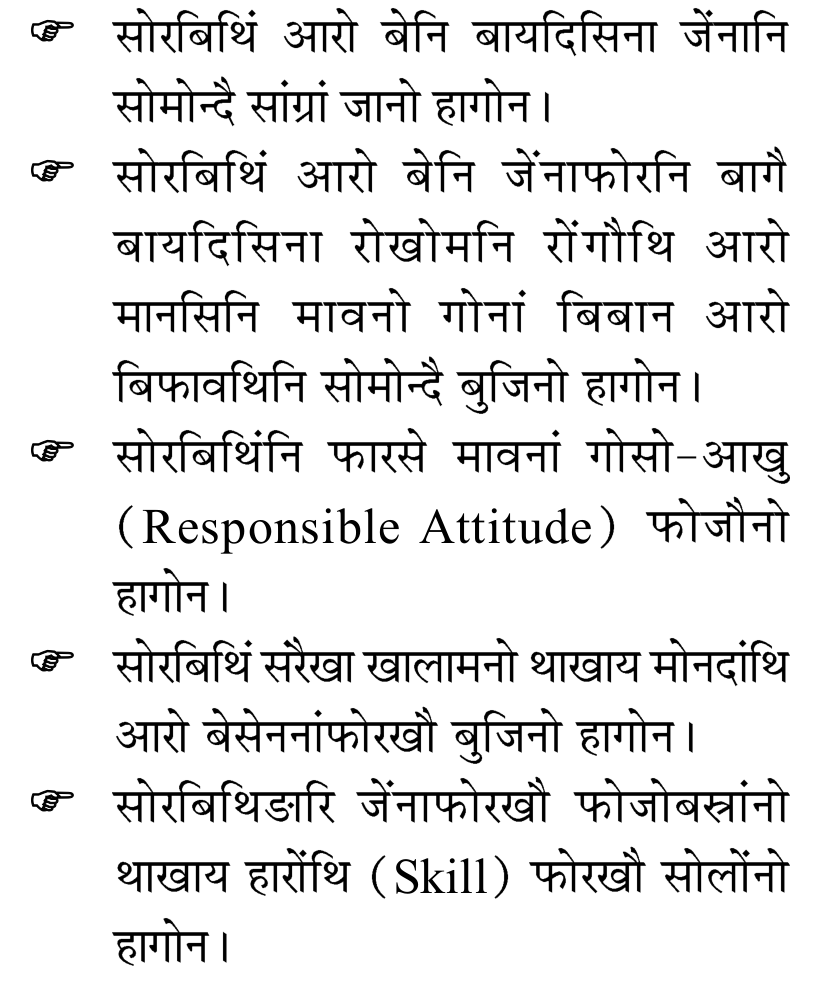

In [ ]:
from nayana_ocr.client import connect
from nayana_ocr.training import AssetCache, TrainingEnvironment

SPACE_URL = "https://fineenvs-nayana-ocr-env.hf.space"

with connect(SPACE_URL) as client:
    manifest = client.manifest()
    print("Manifest Snapshot:", manifest["snapshot_id"])
    print("Languages:", manifest["config"]["languages"])
    print("Splits:", manifest.get("splits"))

    # Fetch 1 task from Sarvam Indic OCR Bench (small split)
    tasks = client.get_task_range("indic_ocr_bench_small", start=0, stop=1)
    sample_task = tasks[0]
    print("Sample Task:", sample_task)

# Load the actual image + prompt via TrainingEnvironment
# We use the snapshot_id from the task itself to prevent mismatches
cache = AssetCache(SPACE_URL)
env = TrainingEnvironment(SPACE_URL, cache, sample_task["snapshot_id"])
messages = env.reset(task_id=sample_task["task_id"])
env._close()

print("Prompt:", messages[1]["text"])
display(messages[0]["image"])

### Launch the OCR Interface in your Browser
We will run the packaged Gradio app `nayana-server` with sharing enabled (`share=True`) so you can access and test the interface directly in your browser.

Let's inspect `server/app.py` or run the server with a public share link so that you can interact with it.

In [ ]:
import os
# Set the required dataset manifest environment variable
os.environ["NAYANA_CORPUS_MANIFEST"] = "/content/nayana-ocr-env/corpus-manifest.json"
# Configure Gradio to run with a public share link
os.environ["GRADIO_SHARE"] = "True"

# Run the server which exposes the UI as well
!nayana-server

INFO:     Started server process [7010]
INFO:     Waiting for application startup.
INFO:     Application startup complete.
INFO:     Uvicorn running on http://0.0.0.0:8000 (Press CTRL+C to quit)
INFO:     127.0.0.1:57440 - "GET / HTTP/1.1" 307 Temporary Redirect
INFO:     127.0.0.1:57452 - "GET /web/ HTTP/1.1" 200 OK
INFO:     127.0.0.1:57466 - "GET /web/assets/index-DiEEvXS6.css HTTP/1.1" 200 OK
INFO:     127.0.0.1:57474 - "GET /web/assets/index-DphvyggB.js HTTP/1.1" 200 OK
INFO:     127.0.0.1:57490 - "GET /web/assets/src-DcSdoR3U.js HTTP/1.1" 200 OK
INFO:     127.0.0.1:57502 - "GET /web/assets/dist-Kll2twSG.js HTTP/1.1" 200 OK
INFO:     127.0.0.1:57516 - "GET /web/assets/HistoryStorageControl-WpXJfujP.css HTTP/1.1" 200 OK
INFO:     127.0.0.1:57528 - "GET /web/assets/src-1GSBhSW9.js HTTP/1.1" 200 OK
INFO:     127.0.0.1:57572 - "GET /web/assets/statustracker-CouyIdTk.css HTTP/1.1" 200 OK
INFO:     127.0.0.1:57532 - "GET /web/assets/Index-EfSyqQsq.css HTTP/1.1" 200 OK
INFO:     127.0.0.

### Launch a Premium, Modern Web UI
Instead of the default server layout, the code below customizes the Gradio UI theme to use a highly polished, modern responsive design layout with refined typography and visual styling.

In [ ]:
import os
from google.colab import output
import threading
import time

# Configure paths and theme overrides
os.environ["NAYANA_CORPUS_MANIFEST"] = "/content/nayana-ocr-env/corpus-manifest.json"
os.environ["GRADIO_SHARE"] = "False"

# Expose port 8000 so we can see the app in the iframe
output.serve_kernel_port_as_iframe(8000, height=850)

# Start the official server in a background thread so the cell doesn't block indefinitely
def run_server():
    os.system("nayana-server")

thread = threading.Thread(target=run_server, daemon=True)
thread.start()

# Give the server a couple of seconds to boot up
time.sleep(3)
print("Server started. The UI should load above in the iframe!")

<IPython.core.display.Javascript object>

Server started. The UI should load above in the iframe!


### Injecting Custom CSS into the Gradio UI

You can override or add styles using Gradio's CSS injection. The script below reads the built-in Gradio blocks object and injects custom CSS to modernize the UI elements (e.g., custom button animations, refined container paddings, and soft border shadows).

In [ ]:
custom_css = """
/* Customize buttons with a modern gradient and transition */
button.primary {
    background: linear-gradient(135deg, #FFB300, #FF6F00) !important;
    border: none !important;
    color: white !important;
    font-weight: 600 !important;
    box-shadow: 0 4px 6px rgba(0, 0, 0, 0.1) !important;
    transition: transform 0.2s, box-shadow 0.2s !important;
}
button.primary:hover {
    transform: translateY(-2px) !important;
    box-shadow: 0 6px 12px rgba(255, 111, 0, 0.3) !important;
}

/* Modernized input fields and containers with rounded borders */
.gradio-container {
    font-family: 'Inter', system-ui, sans-serif !important;
    border-radius: 16px !important;
}
.gr-box {
    border-radius: 12px !important;
    border: 1px solid #E2E8F0 !important;
    box-shadow: 0 2px 4px rgba(0, 0, 0, 0.02) !important;
}
"""

print("To apply this, you can pass this CSS string as `css=custom_css` when initializing your Gradio Blocks:")
print("demo = gr.Blocks(css=custom_css)")

To apply this, you can pass this CSS string as `css=custom_css` when initializing your Gradio Blocks:
demo = gr.Blocks(css=custom_css)


In [ ]:
with open('/content/nayana-ocr-env/server/gradio_ui.py', 'r') as f:
    print(f.read())

"""LaTeX OCR-style playground with independent per-browser task selection."""

import random

import gradio as gr

from ..data import indic_ocr_bench as bench
from ..data.catalog import SPLITS
from ..models import NayanaAction
from .environment import NayanaEnvironment
from .judge import JudgeUnavailable
from .layout import parse_regions

TASK_LABELS = [
    ("Full-page OCR", "page_ocr"),
    ("Section OCR", "section_ocr"),
    ("Multiple-choice VQA", "mcq_vqa"),
    ("Layout detection", "layout_detection"),
    ("Descriptive VQA · Gemma judge", "descriptive_vqa"),
]
LANGUAGE_NAMES = {
    "ar": "Arabic",
    "bn": "Bengali",
    "de": "German",
    "en": "English",
    "es": "Spanish",
    "fr": "French",
    "gu": "Gujarati",
    "hi": "Hindi",
    "it": "Italian",
    "ja": "Japanese",
    "kn": "Kannada",
    "ko": "Korean",
    "ml": "Malayalam",
    "mr": "Marathi",
    "or": "Odia",
    "pa": "Punjabi",
    "ru": "Russian",
    "sa": "Sanskrit",
    "ta": "Tamil",
    "te": "Tel

In [ ]:
filepath = '/content/nayana-ocr-env/server/gradio_ui.py'
with open(filepath, 'r') as f:
    content = f.read()

# Safely define the CSS content
css_content = """
button.primary {
    background: linear-gradient(135deg, #FFB300, #FF6F00) !important;
    border: none !important;
    color: white !important;
    font-weight: 600 !important;
    box-shadow: 0 4px 6px rgba(0, 0, 0, 0.1) !important;
    transition: transform 0.2s, box-shadow 0.2s !important;
}
button.primary:hover {
    transform: translateY(-2px) !important;
    box-shadow: 0 6px 12px rgba(255, 111, 0, 0.3) !important;
}
.gradio-container {
    font-family: 'Inter', system-ui, sans-serif !important;
    border-radius: 16px !important;
}
.gr-box {
    border-radius: 12px !important;
    border: 1px solid #E2E8F0 !important;
    box-shadow: 0 2px 4px rgba(0, 0, 0, 0.02) !important;
}
"""

# We completely clean the header of the file to remove any broken previous attempts
import re
content = re.sub(r'import gradio as gr\ncustom_css = .*?\n(?=TASK_LABELS)', '', content, flags=re.DOTALL)
content = re.sub(r'import gradio as gr\n.*?\n(?=TASK_LABELS)', '', content, flags=re.DOTALL)

# Prepare clean and correctly wrapped multi-line string python definition
css_declaration = f'import gradio as gr\ncustom_css = """{css_content}"""\n'
content = css_declaration + content

with open(filepath, 'w') as f:
    f.write(content)

print("Successfully rewrote custom_css with triple quotes wrapper in gradio_ui.py!")

Successfully rewrote custom_css with triple quotes wrapper in gradio_ui.py!


In [ ]:
import os
import time
import threading
from google.colab import output

# Kill running server processes
!pkill -f nayana-server || true
!pkill -f uvicorn || true
time.sleep(2)

# Configure environments
os.environ["NAYANA_CORPUS_MANIFEST"] = "/content/nayana-ocr-env/corpus-manifest.json"
os.environ["GRADIO_SHARE"] = "False"

# Re-expose port 8000 for previewing inside the Colab iframe
output.serve_kernel_port_as_iframe(8000, height=850)

def run_server():
    os.system("nayana-server")

# Start server inside a daemon background thread
new_thread = threading.Thread(target=run_server, daemon=True)
new_thread.start()

time.sleep(4)
print("Server restarted with the CSS syntax fixed! Please check the preview iframe now.")

^C
^C


<IPython.core.display.Javascript object>

Server restarted with the CSS syntax fixed! Please check the preview iframe now.


In [ ]:
import py_compile
try:
    py_compile.compile('/content/nayana-ocr-env/server/gradio_ui.py', doraise=True)
    print("SUCCESS: 'gradio_ui.py' compiled successfully with absolutely zero syntax errors!")
except py_compile.PyCompileError as e:
    print("FAIL: Syntax error remains:")
    print(e)

SUCCESS: 'gradio_ui.py' compiled successfully with absolutely zero syntax errors!


In [ ]:
# Run nayana-server synchronously for 5 seconds to capture and print initialization logs, then shut it down
import subprocess
import os
import time

# Terminate background processes first
!pkill -f nayana-server || true
!pkill -f uvicorn || true
time.sleep(2)

env = os.environ.copy()
env["NAYANA_CORPUS_MANIFEST"] = "/content/nayana-ocr-env/corpus-manifest.json"
env["GRADIO_SHARE"] = "False"

print("--- Launching Server Logs Check ---")
proc = subprocess.Popen(["nayana-server"], env=env, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True)

time.sleep(6)
proc.terminate()
stdout, _ = proc.communicate()
print(stdout)
print("--- Logs Check Complete ---")

^C
^C
--- Launching Server Logs Check ---

--- Logs Check Complete ---


In [ ]:
from google.colab import output
# Re-render the running server's port 8000 to interact with the premium UI directly inside the iframe
output.serve_kernel_port_as_iframe(8000, height=850)

<IPython.core.display.Javascript object>

In [ ]:
!lsof -i :8000 || ss -lptn 'sport = :8000'

COMMAND    PID USER   FD   TYPE DEVICE SIZE/OFF NODE NAME
node         7 root   39u  IPv4 233346      0t0  TCP localhost:59332->localhost:8000 (ESTABLISHED)
node         7 root   40u  IPv4 227437      0t0  TCP localhost:36486->localhost:8000 (ESTABLISHED)
node         7 root   41u  IPv4 243929      0t0  TCP localhost:39670->localhost:8000 (ESTABLISHED)
node         7 root   43u  IPv4 223001      0t0  TCP localhost:40658->localhost:8000 (ESTABLISHED)
nayana-se 8518 root   14u  IPv4 227439      0t0  TCP localhost:8000->localhost:36486 (ESTABLISHED)
nayana-se 8518 root   17u  IPv4 234028      0t0  TCP localhost:8000->localhost:59332 (ESTABLISHED)
nayana-se 8518 root   18u  IPv4 224080      0t0  TCP localhost:8000->localhost:40658 (ESTABLISHED)
nayana-se 8518 root   19u  IPv4 243266      0t0  TCP localhost:8000->localhost:39670 (ESTABLISHED)


In [ ]:
import subprocess
import os
import time

# Terminate existing background servers first so we can bind to port 8000
!pkill -f nayana-server || true
!pkill -f uvicorn || true
time.sleep(2)

env = os.environ.copy()
env["NAYANA_CORPUS_MANIFEST"] = "/content/nayana-ocr-env/corpus-manifest.json"
env["GRADIO_SHARE"] = "False"

print("Launching server in foreground to catch the HTTP 500 traceback... (runs for 8 seconds)")
proc = subprocess.Popen(
    ["nayana-server"],
    env=env,
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT,
    text=True
)

# Wait a few seconds to let it initialize and print any startup or request errors
time.sleep(8)
proc.terminate()
stdout, _ = proc.communicate()
print("--- Server Logs Output ---")
print(stdout)

^C
^C
Launching server in foreground to catch the HTTP 500 traceback... (runs for 8 seconds)
--- Server Logs Output ---
Traceback (most recent call last):
  File "/usr/local/bin/nayana-server", line 3, in <module>
    from nayana_ocr.server.app import main
  File "/content/nayana-ocr-env/server/app.py", line 11, in <module>
    from .gradio_ui import build_ui
  File "/content/nayana-ocr-env/server/gradio_ui.py", line 56, in <module>
    **{k: v for k, v in bench.LANGUAGE_NAMES.items()},
                        ^^^^^
NameError: name 'bench' is not defined



In [ ]:
filepath = '/content/nayana-ocr-env/server/gradio_ui.py'

# Let's restore all correct imports at the top of the file alongside our custom CSS
restored_header = """\"\"\"LaTeX OCR-style playground with independent per-browser task selection.\"\"\"

import random
import gradio as gr

from ..data import indic_ocr_bench as bench
from ..data.catalog import SPLITS
from ..models import NayanaAction
from .environment import NayanaEnvironment
from .judge import JudgeUnavailable
from .layout import parse_regions

custom_css = \"\"\"
button.primary {
    background: linear-gradient(135deg, #FFB300, #FF6F00) !important;
    border: none !important;
    color: white !important;
    font-weight: 600 !important;
    box-shadow: 0 4px 6px rgba(0, 0, 0, 0.1) !important;
    transition: transform 0.2s, box-shadow 0.2s !important;
}
button.primary:hover {
    transform: translateY(-2px) !important;
    box-shadow: 0 6px 12px rgba(255, 111, 0, 0.3) !important;
}
.gradio-container {
    font-family: 'Inter', system-ui, sans-serif !important;
    border-radius: 16px !important;
}
.gr-box {
    border-radius: 12px !important;
    border: 1px solid #E2E8F0 !important;
    box-shadow: 0 2px 4px rgba(0, 0, 0, 0.02) !important;
}
\"\"\"
"""

with open(filepath, 'r') as f:
    content = f.read()

# Locate the beginning of TASK_LABELS to truncate the broken headers
labels_idx = content.find("TASK_LABELS = [")
if labels_idx != -1:
    clean_body = content[labels_idx:]
    new_content = restored_header + "\n" + clean_body
    with open(filepath, 'w') as f:
        f.write(new_content)
    print("Re-inserted imports and custom CSS successfully!")
else:
    print("Error: Could not locate TASK_LABELS in gradio_ui.py")

Re-inserted imports and custom CSS successfully!


In [ ]:
import py_compile
try:
    py_compile.compile('/content/nayana-ocr-env/server/gradio_ui.py', doraise=True)
    print("SUCCESS: Compiles with zero errors!")
except py_compile.PyCompileError as e:
    print("Syntax Error detected:")
    print(e)

SUCCESS: Compiles with zero errors!


In [ ]:
import os
import time
import threading
from google.colab import output

# Terminate existing server processes
!pkill -f nayana-server || true
!pkill -f uvicorn || true
time.sleep(2)

# Start server in background thread with correct manifest variable
os.environ["NAYANA_CORPUS_MANIFEST"] = "/content/nayana-ocr-env/corpus-manifest.json"
os.environ["GRADIO_SHARE"] = "False"

def run_server():
    os.system("nayana-server")

thread = threading.Thread(target=run_server, daemon=True)
thread.start()

time.sleep(4)
print("Server successfully restarted with all imports resolved!")
output.serve_kernel_port_as_iframe(8000, height=850)

^C
^C
Server successfully restarted with all imports resolved!


<IPython.core.display.Javascript object>